In [ ]:

# ===== CELL 0: KẾT NỐI DRIVE + TỰ ĐỘNG LƯU NOTEBOOK =====

from google.colab import drive, _message
from IPython import get_ipython
import os
import json
import nbformat
from nbconvert import HTMLExporter

# 1. KẾT NỐI GOOGLE DRIVE
drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/Phishing_URL_Project"

os.makedirs(PROJECT_DIR, exist_ok=True)
os.chdir(PROJECT_DIR)

print("✅ Đã kết nối Google Drive")
print("📁 Project:", os.getcwd())


# 2. HÀM TỰ ĐỘNG LƯU KẾT QUẢ
def tu_luu_ket_qua(result=None):
    if not os.path.isdir("/content/drive/MyDrive"):
        return

    try:
        # Lấy notebook hiện tại, bao gồm output
        response = _message.blocking_request(
            "get_ipynb",
            timeout_sec=30
        )
        nb = nbformat.from_dict(response["ipynb"])

        # Lưu notebook IPYNB
        notebook_path = os.path.join(
            PROJECT_DIR, "ket_qua_notebook.ipynb"
        )

        with open(notebook_path, "w", encoding="utf-8") as f:
            nbformat.write(nb, f)

        # Chuyển notebook thành HTML
        html, _ = HTMLExporter().from_notebook_node(nb)

        html_path = os.path.join(
            PROJECT_DIR, "ket_qua_notebook.html"
        )

        with open(html_path, "w", encoding="utf-8") as f:
            f.write(html)

    except Exception as e:
        print("⚠️ Tự lưu thất bại:", e)


# 3. ĐĂNG KÝ TỰ LƯU SAU MỖI CELL
ip = get_ipython()

# Tránh đăng ký trùng khi chạy lại CELL 0
for cb in list(ip.events.callbacks["post_run_cell"]):
    if getattr(cb, "__name__", "") == "tu_luu_ket_qua":
        ip.events.unregister("post_run_cell", cb)

ip.events.register("post_run_cell", tu_luu_ket_qua)

print("✅ Đã bật chế độ tự động lưu")
print("📂 Thư mục:", PROJECT_DIR)
print("📄 ket_qua_notebook.ipynb")
print("🌐 ket_qua_notebook.html")
print("✅ Các CELL tiếp theo sẽ được tự động lưu sau khi chạy")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Đã kết nối Google Drive
📁 Project: /content/drive/MyDrive/Phishing_URL_Project
✅ Đã bật chế độ tự động lưu
📂 Thư mục: /content/drive/MyDrive/Phishing_URL_Project
📄 ket_qua_notebook.ipynb
🌐 ket_qua_notebook.html
✅ Các CELL tiếp theo sẽ được tự động lưu sau khi chạy
⚠️ Tự lưu thất bại: expected string or bytes-like object, got 'list'


In [ ]:
# ===== CELL 1: ĐỌC DATASET TỪ GOOGLE DRIVE =====

import os
import pandas as pd
from IPython.display import display

dataset_path = os.path.join(
    PROJECT_DIR,
    "PhiUSIIL_Phishing_URL_Dataset.csv"
)

if not os.path.exists(dataset_path):
    raise FileNotFoundError(
        f"Không tìm thấy dataset tại:\n{dataset_path}\n"
        "Hãy upload file CSV vào thư mục Phishing_URL_Project trên Google Drive."
    )

# Kiểm tra tên cột
header = pd.read_csv(dataset_path, nrows=0)

required_columns = {"URL", "label"}
missing_columns = required_columns.difference(header.columns)

if missing_columns:
    raise ValueError(
        f"Dataset thiếu các cột bắt buộc: {sorted(missing_columns)}"
    )

# Chỉ đọc hai cột dùng để train
df = pd.read_csv(
    dataset_path,
    usecols=["URL", "label"],
    low_memory=False
)

print("Đã đọc dataset:", dataset_path)
print("Kích thước dataset:", df.shape)
print("Các cột được dùng:", df.columns.tolist())

display(df.head())

Đã đọc dataset: /content/drive/MyDrive/Phishing_URL_Project/PhiUSIIL_Phishing_URL_Dataset.csv
Kích thước dataset: (235795, 2)
Các cột được dùng: ['URL', 'label']


,URL,label
0,https://www.southbankmosaics.com,1
1,https://www.uni-mainz.de,1
2,https://www.voicefmradio.co.uk,1
3,https://www.sfnmjournal.com,1
4,https://www.rewildingargentina.org,1


⚠️ Tự lưu thất bại: expected string or bytes-like object, got 'list'


In [ ]:
# ===== CELL 2: KIỂM TRA DATASET =====

print("===== KÍCH THƯỚC =====")

print("Số dòng:", df.shape[0])
print("Số cột:", df.shape[1])


print("\n===== PHÂN BỐ LABEL GỐC =====")

display(
    df["label"]
    .value_counts(dropna=False)
    .rename("count")
    .to_frame()
)

display(
    (
        df["label"]
        .value_counts(
            normalize=True,
            dropna=False
        ) * 100
    )
    .round(2)
    .rename("percent")
    .to_frame()
)


print("\n===== MISSING VALUES =====")

missing = df.isna().sum()

display(
    missing[missing > 0]
    .rename("missing_count")
    .to_frame()
)


print("\n===== DUPLICATE =====")

print(
    "Số dòng trùng hoàn toàn:",
    int(df.duplicated().sum())
)

print(
    "Số URL bị trùng:",
    int(df["URL"].duplicated().sum())
)


print("\n===== KIỂU DỮ LIỆU LABEL =====")

print(df["label"].dtype)

print(
    "Các giá trị label:",
    sorted(
        df["label"]
        .dropna()
        .unique()
        .tolist()
    )
)

===== KÍCH THƯỚC =====
Số dòng: 235795
Số cột: 2

===== PHÂN BỐ LABEL GỐC =====


,count
label,
1,134850
0,100945


,percent
label,
1,57.19
0,42.81



===== MISSING VALUES =====


,missing_count



===== DUPLICATE =====
Số dòng trùng hoàn toàn: 425
Số URL bị trùng: 425

===== KIỂU DỮ LIỆU LABEL =====
int64
Các giá trị label: [0, 1]
⚠️ Tự lưu thất bại: expected string or bytes-like object, got 'list'


In [ ]:
# ===== CELL 3: URL TRÙNG + LABEL CONFLICT =====

check_df = df[["URL", "label"]].copy()

# Chuẩn hóa URL trước khi kiểm tra
check_df["URL"] = (
    check_df["URL"]
    .astype("string")
    .str.strip()
)

# URL trùng
dup_mask = check_df["URL"].duplicated(
    keep=False
)

dup_urls = (
    check_df
    .loc[dup_mask]
    .sort_values("URL")
)

# Kiểm tra 1 URL có nhiều label hay không
label_per_url = (
    check_df
    .dropna(subset=["URL"])
    .groupby("URL")["label"]
    .nunique()
)

conflict_urls = label_per_url[
    label_per_url > 1
]

print(
    "Tổng số dòng thuộc URL bị trùng:",
    len(dup_urls)
)

print(
    "Số URL duy nhất bị trùng:",
    dup_urls["URL"].nunique()
)

print(
    "Số URL có label mâu thuẫn:",
    len(conflict_urls)
)


if len(conflict_urls) > 0:

    print(
        "\nMột số URL bị gán nhiều label:"
    )

    display(
        check_df[
            check_df["URL"]
            .isin(conflict_urls.index)
        ]
        .sort_values("URL")
        .head(20)
    )

else:

    print(
        "Không có URL nào bị gán "
        "label mâu thuẫn ✅"
    )


print("\nMột số URL bị trùng:")

display(
    dup_urls.head(20)
)

Tổng số dòng thuộc URL bị trùng: 850
Số URL duy nhất bị trùng: 425
Số URL có label mâu thuẫn: 0
Không có URL nào bị gán label mâu thuẫn ✅

Một số URL bị trùng:


,URL,label
219489,http://2f3a.reicrut-chat.workers.dev/,0
57609,http://2f3a.reicrut-chat.workers.dev/,0
227564,http://34.149.138.117/,0
27166,http://34.149.138.117/,0
147448,http://595221.selcdn.ru/qwerty-ohdhdjejnnad-na...,0
189978,http://595221.selcdn.ru/qwerty-ohdhdjejnnad-na...,0
57315,http://595221.selcdn.ru/qwerty-ohdhdjejnnad-na...,0
31955,http://595221.selcdn.ru/qwerty-ohdhdjejnnad-na...,0
197956,http://91.239.125.28/postchs/sms.php,0
126246,http://91.239.125.28/postchs/sms.php,0


⚠️ Tự lưu thất bại: expected string or bytes-like object, got 'list'


In [ ]:
# ===== CELL 4: CLEAN DATASET =====

df_clean = df[["URL", "label"]].copy()

# Chuẩn hóa URL
df_clean["URL"] = (
    df_clean["URL"]
    .astype("string")
    .str.strip()
)

# Chuẩn hóa label
df_clean["label"] = pd.to_numeric(
    df_clean["label"],
    errors="coerce"
)

# Bỏ missing
df_clean = df_clean.dropna(
    subset=["URL", "label"]
)

# Bỏ URL rỗng
df_clean = df_clean[
    df_clean["URL"].str.len() > 0
]

# Label thành int
df_clean["label"] = (
    df_clean["label"]
    .astype(int)
)

# Kiểm tra label hợp lệ
if not set(
    df_clean["label"].unique()
).issubset({0, 1}):

    raise ValueError(
        "Label phải chỉ gồm 0 và 1."
    )

# Nếu có URL conflict -> bỏ
if len(conflict_urls) > 0:

    df_clean = df_clean[
        ~df_clean["URL"]
        .isin(conflict_urls.index)
    ]

# URL trùng nhưng cùng label -> giữ 1
df_clean = (
    df_clean
    .drop_duplicates(
        subset="URL",
        keep="first"
    )
    .reset_index(drop=True)
)

# ===== GIỮ NGUYÊN LABEL GỐC =====
# 0 = Phishing
# 1 = Legitimate

print("Shape sau clean:", df_clean.shape)

print("\nPhân bố label sau clean:")

display(
    df_clean["label"]
    .value_counts()
    .sort_index()
    .rename("count")
    .to_frame()
)

print("\nTỷ lệ (%):")

display(
    (
        df_clean["label"]
        .value_counts(
            normalize=True
        )
        .sort_index() * 100
    )
    .round(2)
    .rename("percent")
    .to_frame()
)

print(
    "Missing URL:",
    int(
        df_clean["URL"]
        .isna()
        .sum()
    )
)

print(
    "URL trùng còn lại:",
    int(
        df_clean["URL"]
        .duplicated()
        .sum()
    )
)

print(
    "Label dùng để train:",
    sorted(
        df_clean["label"]
        .unique()
        .tolist()
    )
)

print("\nQuy ước label:")
print("0 = Phishing")
print("1 = Legitimate")

display(df_clean.head())

Shape sau clean: (235370, 2)

Phân bố label sau clean:


,count
label,
0,100520
1,134850



Tỷ lệ (%):


,percent
label,
0,42.71
1,57.29


Missing URL: 0
URL trùng còn lại: 0
Label dùng để train: [0, 1]

Quy ước label:
0 = Phishing
1 = Legitimate


,URL,label
0,https://www.southbankmosaics.com,1
1,https://www.uni-mainz.de,1
2,https://www.voicefmradio.co.uk,1
3,https://www.sfnmjournal.com,1
4,https://www.rewildingargentina.org,1


⚠️ Tự lưu thất bại: expected string or bytes-like object, got 'list'


In [ ]:
# ===== CELL 5: EDA CƠ BẢN =====

import numpy as np

eda = df_clean.copy()

# Một số đặc trưng đơn giản để phân tích
eda["url_length"] = eda["URL"].str.len()
eda["num_dots"] = eda["URL"].str.count(r"\.")
eda["num_hyphens"] = eda["URL"].str.count("-")
eda["num_slashes"] = eda["URL"].str.count("/")
eda["num_digits"] = eda["URL"].str.count(r"\d")
eda["num_at"] = eda["URL"].str.count("@")
eda["num_question"] = eda["URL"].str.count(r"\?")
eda["num_equal"] = eda["URL"].str.count("=")

# GIỮ NGUYÊN LABEL GỐC
# 0 = Phishing
# 1 = Legitimate
eda["class"] = eda["label"].map({
    0: "Phishing",
    1: "Legitimate"
})

eda_features = [
    "url_length",
    "num_dots",
    "num_hyphens",
    "num_slashes",
    "num_digits",
    "num_at",
    "num_question",
    "num_equal"
]

print("===== THỐNG KÊ THEO CLASS =====")

display(
    eda.groupby("class")[eda_features]
       .mean()
       .round(2)
)

print("\n===== THỐNG KÊ URL LENGTH =====")

display(
    eda.groupby("class")["url_length"]
       .describe()
       .round(2)
)

===== THỐNG KÊ THEO CLASS =====


,url_length,num_dots,num_hyphens,num_slashes,num_digits,num_at,num_question,num_equal
class,,,,,,,,
Legitimate,27.23,2.16,0.08,2.0,0.05,0.0,0.0,0.0
Phishing,46.22,2.38,0.71,3.02,4.34,0.02,0.07,0.15



===== THỐNG KÊ URL LENGTH =====


,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
Legitimate,134850.0,27.23,4.82,16.0,24.0,27.0,30.0,58.0
Phishing,100520.0,46.22,61.18,14.0,26.0,34.0,48.0,6097.0


⚠️ Tự lưu thất bại: expected string or bytes-like object, got 'list'


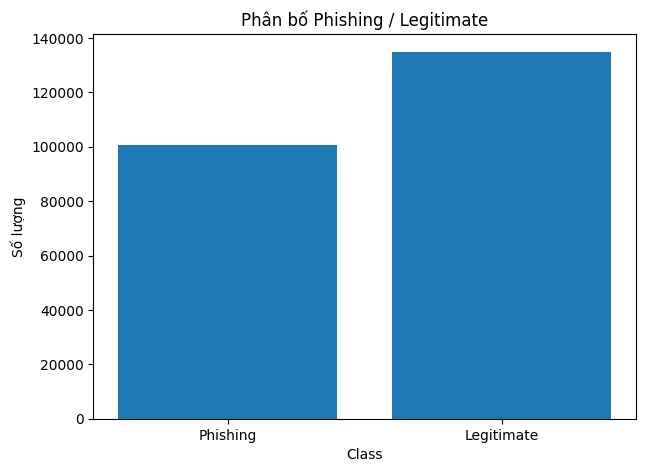

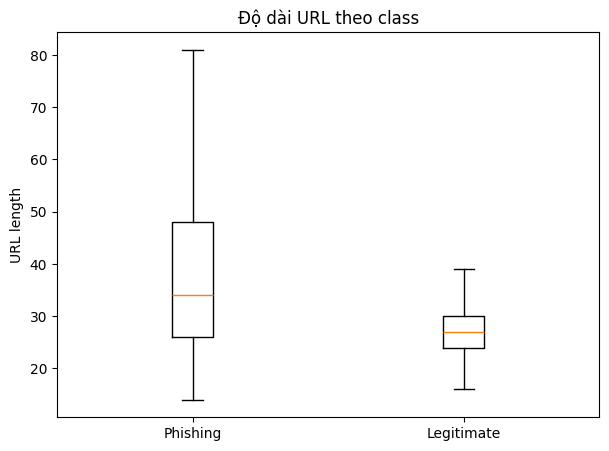

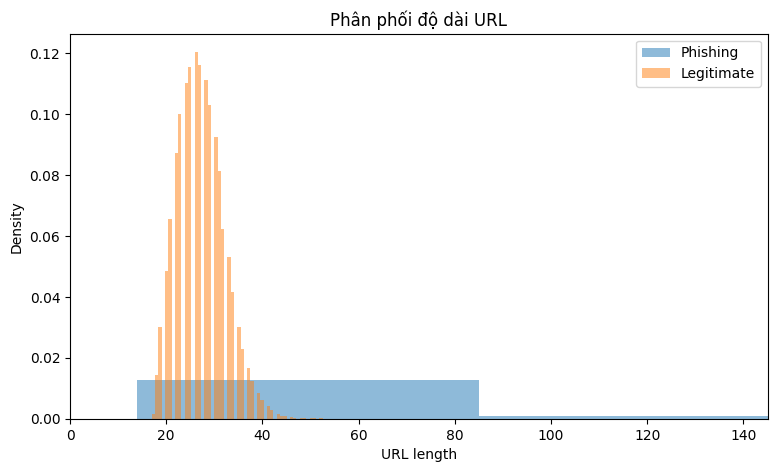

⚠️ Tự lưu thất bại: expected string or bytes-like object, got 'list'


In [ ]:
# ===== CELL 6: BIỂU ĐỒ EDA =====

import matplotlib.pyplot as plt

# =========================
# 1. PHÂN BỐ CLASS
# =========================

class_counts = (
    eda["class"]
    .value_counts()
    .reindex([
        "Phishing",
        "Legitimate"
    ])
)

plt.figure(figsize=(7, 5))

plt.bar(
    class_counts.index,
    class_counts.values
)

plt.title("Phân bố Phishing / Legitimate")
plt.xlabel("Class")
plt.ylabel("Số lượng")

plt.show()


# =========================
# 2. BOXPLOT URL LENGTH
# =========================

phishing_length = eda.loc[
    eda["label"] == 0,
    "url_length"
]

legitimate_length = eda.loc[
    eda["label"] == 1,
    "url_length"
]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [
        phishing_length,
        legitimate_length
    ],
    tick_labels=[
        "Phishing",
        "Legitimate"
    ],
    showfliers=False
)

plt.title("Độ dài URL theo class")
plt.ylabel("URL length")

plt.show()


# =========================
# 3. HISTOGRAM URL LENGTH
# =========================

sample_for_plot = eda.sample(
    min(100_000, len(eda)),
    random_state=42
)

plt.figure(figsize=(9, 5))

plt.hist(
    sample_for_plot.loc[
        sample_for_plot["label"] == 0,
        "url_length"
    ],
    bins=60,
    density=True,
    alpha=0.5,
    label="Phishing"
)

plt.hist(
    sample_for_plot.loc[
        sample_for_plot["label"] == 1,
        "url_length"
    ],
    bins=60,
    density=True,
    alpha=0.5,
    label="Legitimate"
)

plt.title("Phân phối độ dài URL")
plt.xlabel("URL length")
plt.ylabel("Density")

plt.legend()

# Không cho URL cực dài làm biểu đồ bị ép
plt.xlim(
    0,
    sample_for_plot["url_length"].quantile(0.99)
)

plt.show()

In [ ]:
# ===== CELL 7: PHÂN TÍCH OUTLIER URL LENGTH =====

print("===== URL LENGTH PERCENTILES =====")

for label, name in [
    (0, "Phishing"),
    (1, "Legitimate")
]:

    values = eda.loc[
        eda["label"] == label,
        "url_length"
    ]

    print(f"\n{name}:")

    print("50% :", values.quantile(0.50))
    print("75% :", values.quantile(0.75))
    print("90% :", values.quantile(0.90))
    print("95% :", values.quantile(0.95))
    print("99% :", values.quantile(0.99))
    print("Max :", values.max())


print("\n===== 10 URL DÀI NHẤT =====")

display(
    eda.sort_values(
        "url_length",
        ascending=False
    )[
        [
            "URL",
            "label",
            "class",
            "url_length"
        ]
    ].head(10)
)

print(
    "\nKhông tự động xóa outlier vì "
    "độ dài URL có thể là tín hiệu hữu ích."
)

===== URL LENGTH PERCENTILES =====

Phishing:
50% : 34.0
75% : 48.0
90% : 80.0
95% : 99.0
99% : 231.0
Max : 6097

Legitimate:
50% : 27.0
75% : 30.0
90% : 34.0
95% : 36.0
99% : 40.0
Max : 58

===== 10 URL DÀI NHẤT =====


,URL,label,class,url_length
102859,https://xwebhostapp.github.io/freehost//#eyj2z...,0,Phishing,6097
9650,https://b4e921f0.sso-mailsrvr-4344e5teed.pages...,0,Phishing,5795
150704,https://bodhicardstech.com/beta/wx%20qz%20xx%2...,0,Phishing,4274
145238,https://inspirationalatmospheres.com/qxzrrr%20...,0,Phishing,4247
152564,https://bodhicardstech.com/beta/wx%20qz%20xx%2...,0,Phishing,4054
146757,http://www.inspirationalatmospheres.com/qxzrrr...,0,Phishing,4036
157101,https://inspirationalatmospheres.com/qxzrrr%20...,0,Phishing,4033
149634,https://ssiol.lt.emlnk.com/prod/link-tracker?n...,0,Phishing,3473
184540,https://ssiol.lt.emlnk.com/prod/link-tracker?n...,0,Phishing,1769
233973,https://u31696126.ct.sendgrid.net/ls/click?upn...,0,Phishing,1428



Không tự động xóa outlier vì độ dài URL có thể là tín hiệu hữu ích.
⚠️ Tự lưu thất bại: expected string or bytes-like object, got 'list'


In [ ]:
# ===== CELL 8: LƯU DATASET CLEAN =====

clean_path = os.path.join(
    PROJECT_DIR,
    "phiusiil_clean.csv"
)

df_clean.to_csv(
    clean_path,
    index=False
)

print("✅ Đã lưu:", clean_path)
print("Shape:", df_clean.shape)

print("\nQuy ước label:")
print("0 = Phishing")
print("1 = Legitimate")

✅ Đã lưu: /content/drive/MyDrive/Phishing_URL_Project/phiusiil_clean.csv
Shape: (235370, 2)

Quy ước label:
0 = Phishing
1 = Legitimate
⚠️ Tự lưu thất bại: expected string or bytes-like object, got 'list'


In [ ]:
# ===== CELL 9: FEATURE ENGINEERING =====

import ipaddress
import math

from collections import Counter
from urllib.parse import urlsplit


SUSPICIOUS_WORDS = [
    "login",
    "signin",
    "verify",
    "verification",
    "secure",
    "account",
    "update",
    "confirm",
    "password",
    "credential",
    "bank",
    "wallet",
    "payment",
    "invoice",
    "support",
    "auth",
    "recover",
    "security"
]


# =========================
# Shannon Entropy
# =========================

def shannon_entropy(text):

    if not text:
        return 0.0

    counts = Counter(text)
    length = len(text)

    return -sum(
        (count / length)
        * math.log2(count / length)

        for count in counts.values()
    )


# =========================
# Kiểm tra hostname là IP
# =========================

def is_ip_address(hostname):

    try:
        ipaddress.ip_address(hostname)
        return 1

    except (ValueError, TypeError):
        return 0


# =========================
# Trích 27 feature
# =========================

def extract_url_features(url):

    url = str(url)

    url_lower = url.lower()

    # Nếu URL không có scheme
    parse_target = (
        url
        if "://" in url
        else "//" + url
    )

    try:

        parsed = urlsplit(parse_target)

        hostname = parsed.hostname or ""
        path = parsed.path or ""
        query = parsed.query or ""

    except (ValueError, TypeError):

        hostname = ""
        path = ""
        query = ""


    # Đếm chữ / số / ký tự đặc biệt
    num_digits = sum(
        char.isdigit()
        for char in url
    )

    num_letters = sum(
        char.isalpha()
        for char in url
    )

    num_special_chars = sum(
        not char.isalnum()
        for char in url
    )


    # Số subdomain gần đúng
    domain_parts = (
        hostname.split(".")
        if hostname
        else []
    )

    num_subdomains = max(
        len(domain_parts) - 2,
        0
    )


    # Số từ đáng ngờ
    suspicious_word_count = sum(
        word in url_lower
        for word in SUSPICIOUS_WORDS
    )


    features = {

        # 1
        "url_length":
            len(url),

        # 2
        "hostname_length":
            len(hostname),

        # 3
        "path_length":
            len(path),

        # 4
        "query_length":
            len(query),

        # 5
        "num_dots":
            url.count("."),

        # 6
        "num_hyphens":
            url.count("-"),

        # 7
        "num_underscores":
            url.count("_"),

        # 8
        "num_slashes":
            url.count("/"),

        # 9
        "num_at":
            url.count("@"),

        # 10
        "num_question":
            url.count("?"),

        # 11
        "num_equal":
            url.count("="),

        # 12
        "num_ampersand":
            url.count("&"),

        # 13
        "num_percent":
            url.count("%"),

        # 14
        "num_digits":
            num_digits,

        # 15
        "num_letters":
            num_letters,

        # 16
        "num_special_chars":
            num_special_chars,

        # 17
        "digit_ratio":
            num_digits / max(len(url), 1),

        # 18
        "letter_ratio":
            num_letters / max(len(url), 1),

        # 19
        "num_subdomains":
            num_subdomains,

        # 20
        "has_ip":
            is_ip_address(hostname),

        # 21
        "has_https":
            int(
                url_lower.startswith(
                    "https://"
                )
            ),

        # 22
        "has_at":
            int("@" in url),

        # 23
        "has_double_slash_path":
            int("//" in path),

        # 24
        "has_punycode":
            int(
                "xn--"
                in hostname.lower()
            ),

        # 25
        "suspicious_word_count":
            suspicious_word_count,

        # 26
        "entropy":
            shannon_entropy(url),

        # 27
        "log_url_length":
            np.log1p(len(url))
    }

    return features

⚠️ Tự lưu thất bại: expected string or bytes-like object, got 'list'


In [ ]:
# ===== CELL 9.1: TẠO 27 FEATURES =====

print("Đang trích xuất 27 features...")

feature_rows = [
    extract_url_features(url)
    for url in df_clean["URL"]
]

X_features = (
    pd.DataFrame(feature_rows)
    .astype("float32")
)

# GIỮ LABEL GỐC
# 0 = Phishing
# 1 = Legitimate
y = (
    df_clean["label"]
    .astype("int8")
    .copy()
)


# =========================
# Kiểm tra
# =========================

assert X_features.shape[1] == 27, (
    f"Đang có {X_features.shape[1]} features, "
    "cần đúng 27."
)

assert X_features.isna().sum().sum() == 0, (
    "Features đang có missing value."
)


print("\n✅ HOÀN TẤT")

print("Số mẫu:", X_features.shape[0])
print("Số feature:", X_features.shape[1])

print("\nDanh sách 27 features:")

print(
    X_features.columns.tolist()
)

print("\n5 dòng đầu:")

display(
    X_features.head()
)

print("\nPhân bố target:")

display(
    y.value_counts()
     .sort_index()
     .rename("count")
     .to_frame()
)

print("0 = Phishing")
print("1 = Legitimate")

Đang trích xuất 27 features...

✅ HOÀN TẤT
Số mẫu: 235370
Số feature: 27

Danh sách 27 features:
['url_length', 'hostname_length', 'path_length', 'query_length', 'num_dots', 'num_hyphens', 'num_underscores', 'num_slashes', 'num_at', 'num_question', 'num_equal', 'num_ampersand', 'num_percent', 'num_digits', 'num_letters', 'num_special_chars', 'digit_ratio', 'letter_ratio', 'num_subdomains', 'has_ip', 'has_https', 'has_at', 'has_double_slash_path', 'has_punycode', 'suspicious_word_count', 'entropy', 'log_url_length']

5 dòng đầu:


,url_length,hostname_length,path_length,query_length,num_dots,num_hyphens,num_underscores,num_slashes,num_at,num_question,...,letter_ratio,num_subdomains,has_ip,has_https,has_at,has_double_slash_path,has_punycode,suspicious_word_count,entropy,log_url_length
0,32.0,24.0,0.0,0.0,2.0,0.0,0.0,2.0,0.0,0.0,...,0.843750,1.0,0.0,1.0,0.0,0.0,0.0,1.0,3.929229,3.496508
1,24.0,16.0,0.0,0.0,2.0,1.0,0.0,2.0,0.0,0.0,...,0.750000,1.0,0.0,1.0,0.0,0.0,0.0,0.0,3.970176,3.218876
2,30.0,22.0,0.0,0.0,3.0,0.0,0.0,2.0,0.0,0.0,...,0.800000,2.0,0.0,1.0,0.0,0.0,0.0,0.0,4.164735,3.433987
3,27.0,19.0,0.0,0.0,2.0,0.0,0.0,2.0,0.0,0.0,...,0.814815,1.0,0.0,1.0,0.0,0.0,0.0,0.0,4.060262,3.332205
4,34.0,26.0,0.0,0.0,2.0,0.0,0.0,2.0,0.0,0.0,...,0.852941,1.0,0.0,1.0,0.0,0.0,0.0,0.0,3.917626,3.555348



Phân bố target:


,count
label,
0,100520
1,134850


0 = Phishing
1 = Legitimate
⚠️ Tự lưu thất bại: expected string or bytes-like object, got 'list'


In [ ]:
# ===== CELL 9.2: LƯU FEATURES =====

features_path = os.path.join(
    PROJECT_DIR,
    "phiusiil_27_lexical_features.csv"
)

features_export = pd.concat(
    [
        X_features,
        y.rename("label")
    ],
    axis=1
)

features_export.to_csv(
    features_path,
    index=False
)

print("✅ Đã lưu:")
print(features_path)

print("Shape:", features_export.shape)

✅ Đã lưu:
/content/drive/MyDrive/Phishing_URL_Project/phiusiil_27_lexical_features.csv
Shape: (235370, 28)
⚠️ Tự lưu thất bại: expected string or bytes-like object, got 'list'


In [ ]:
# ===== CELL 10: TRAIN / VALIDATION / TEST =====

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42


# =========================
# 70% TRAIN
# =========================

X_train, X_temp, y_train, y_temp = train_test_split(
    X_features,
    y,

    test_size=0.30,

    stratify=y,

    random_state=RANDOM_STATE
)


# =========================
# 15% VALIDATION
# 15% TEST
# =========================

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,

    test_size=0.50,

    stratify=y_temp,

    random_state=RANDOM_STATE
)


print(
    "Train:",
    X_train.shape,
    f"({len(X_train) / len(X_features):.1%})"
)

print(
    "Validation:",
    X_val.shape,
    f"({len(X_val) / len(X_features):.1%})"
)

print(
    "Test:",
    X_test.shape,
    f"({len(X_test) / len(X_features):.1%})"
)


print("\n===== TRAIN LABEL =====")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True).round(4))

print("\n===== VALIDATION LABEL =====")
print(y_val.value_counts())
print(y_val.value_counts(normalize=True).round(4))

print("\n===== TEST LABEL =====")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True).round(4))

Train: (164759, 27) (70.0%)
Validation: (35305, 27) (15.0%)
Test: (35306, 27) (15.0%)

===== TRAIN LABEL =====
label
1    94395
0    70364
Name: count, dtype: int64
label
1    0.5729
0    0.4271
Name: proportion, dtype: float64

===== VALIDATION LABEL =====
label
1    20227
0    15078
Name: count, dtype: int64
label
1    0.5729
0    0.4271
Name: proportion, dtype: float64

===== TEST LABEL =====
label
1    20228
0    15078
Name: count, dtype: int64
label
1    0.5729
0    0.4271
Name: proportion, dtype: float64
⚠️ Tự lưu thất bại: expected string or bytes-like object, got 'list'


In [ ]:
# ===== CELL 11: KHỞI TẠO 3 MÔ HÌNH =====

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC


models = {

    # =========================
    # Logistic Regression
    # =========================

    "Logistic Regression": Pipeline([

        (
            "scaler",
            StandardScaler()
        ),

        (
            "model",
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=RANDOM_STATE
            )
        )

    ]),


    # =========================
    # Random Forest
    # =========================

    "Random Forest": RandomForestClassifier(

        n_estimators=300,

        class_weight="balanced_subsample",

        n_jobs=-1,

        random_state=RANDOM_STATE

    ),


    # =========================
    # Linear SVM
    # =========================

    "SVM (LinearSVC)": Pipeline([

        (
            "scaler",
            StandardScaler()
        ),

        (
            "model",
            LinearSVC(

                C=1.0,

                class_weight="balanced",

                max_iter=5000,

                random_state=RANDOM_STATE
            )
        )

    ])
}


print("===== DANH SÁCH MODEL =====")

for name in models:
    print("-", name)

===== DANH SÁCH MODEL =====
- Logistic Regression
- Random Forest
- SVM (LinearSVC)
⚠️ Tự lưu thất bại: expected string or bytes-like object, got 'list'


In [ ]:
# ===== CELL 11.1: TRAIN 3 MODEL =====

for name, model in models.items():

    print(
        f"\nĐang train {name}..."
    )

    model.fit(
        X_train,
        y_train
    )

    print(
        f"✅ Hoàn tất {name}"
    )


Đang train Logistic Regression...
✅ Hoàn tất Logistic Regression

Đang train Random Forest...


KeyboardInterrupt: 

⚠️ Tự lưu thất bại: expected string or bytes-like object, got 'list'


In [ ]:
# ===== CELL 12: HÀM ĐÁNH GIÁ =====

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score
)


# ============================================
# Score dành riêng cho class 0 = PHISHING
# ============================================

def phishing_score_source(model, X):

    # Logistic Regression / Random Forest
    if hasattr(model, "predict_proba"):

        probabilities = model.predict_proba(X)

        # Tìm vị trí của class 0
        phishing_index = list(
            model.classes_
        ).index(0)

        return probabilities[
            :,
            phishing_index
        ]


    # LinearSVC
    #
    # decision_function > 0 mặc định nghiêng về class 1.
    # Nhưng Phishing = class 0.
    #
    # Vì vậy đảo dấu để score cao = nghiêng về Phishing.
    scores = model.decision_function(X)

    return -scores


# ============================================
# Hàm evaluate
# ============================================

def evaluate_model(
    model,
    X_eval,
    y_eval,
    model_name,
    split_name
):

    predictions = model.predict(
        X_eval
    )

    phishing_scores = phishing_score_source(
        model,
        X_eval
    )


    # ROC-AUC cần target:
    # phishing = 1
    # legitimate = 0
    #
    # Chỉ dùng tạm cho phép tính ROC-AUC,
    # KHÔNG thay đổi label dataset.
    y_phishing_binary = (
        y_eval == 0
    ).astype(int)


    result = {

        "model":
            model_name,

        "split":
            split_name,

        "accuracy":
            accuracy_score(
                y_eval,
                predictions
            ),

        # PHISHING = 0
        "precision_phishing":
            precision_score(
                y_eval,
                predictions,
                pos_label=0,
                zero_division=0
            ),

        "recall_phishing":
            recall_score(
                y_eval,
                predictions,
                pos_label=0,
                zero_division=0
            ),

        "f1_phishing":
            f1_score(
                y_eval,
                predictions,
                pos_label=0,
                zero_division=0
            ),

        "roc_auc_phishing":
            roc_auc_score(
                y_phishing_binary,
                phishing_scores
            )
    }


    print(
        f"\n===== {model_name} | "
        f"{split_name} ====="
    )


    print(
        classification_report(
            y_eval,
            predictions,

            labels=[0, 1],

            target_names=[
                "Phishing (0)",
                "Legitimate (1)"
            ],

            zero_division=0
        )
    )


    print("Confusion Matrix:")

    print(
        confusion_matrix(
            y_eval,
            predictions,
            labels=[0, 1]
        )
    )


    return result

In [ ]:
# ===== CELL 12.1: ĐÁNH GIÁ VALIDATION =====

validation_results = [

    evaluate_model(
        model,

        X_val,

        y_val,

        name,

        "validation"
    )

    for name, model
    in models.items()
]


validation_table = (
    pd.DataFrame(
        validation_results
    )

    .sort_values(
        "f1_phishing",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


print(
    "\n===== SO SÁNH 3 MODEL ====="
)

display(
    validation_table.round(4)
)

In [ ]:
# ===== CELL 12.2: CONFUSION MATRIX CHO 3 MODEL =====

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

for name, model in models.items():

    # Dự đoán trên Validation
    y_pred = model.predict(X_val)

    # Confusion Matrix
    cm = confusion_matrix(
        y_val,
        y_pred,
        labels=[0, 1]
    )

    # Vẽ
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            "Phishing (0)",
            "Legitimate (1)"
        ]
    )

    fig, ax = plt.subplots(figsize=(6, 5))

    disp.plot(
        ax=ax,
        values_format="d"
    )

    plt.title(
        f"Confusion Matrix - {name}\nValidation Set"
    )

    plt.tight_layout()
    plt.show()

In [ ]:
# ===== CELL 13: CHỌN MODEL TỐT NHẤT =====

best_name = (
    validation_table
    .iloc[0]["model"]
)

best_model = models[
    best_name
]

print(
    "🏆 MODEL TỐT NHẤT THEO F1 PHISHING:"
)

print(
    best_name
)

print(
    "\nValidation F1 Phishing:"
)

print(
    validation_table
    .iloc[0]["f1_phishing"]
)

In [ ]:
# ===== CELL 13.1: TEST CUỐI =====

# Gộp Train + Validation
X_train_val = pd.concat(
    [
        X_train,
        X_val
    ],
    axis=0
)

y_train_val = pd.concat(
    [
        y_train,
        y_val
    ],
    axis=0
)


print(
    "Đang train lại model tốt nhất "
    "trên Train + Validation..."
)


best_model.fit(
    X_train_val,
    y_train_val
)


print(
    "✅ Refit hoàn tất"
)


print(
    "\nĐánh giá trên TEST SET..."
)


test_result = evaluate_model(

    best_model,

    X_test,

    y_test,

    best_name,

    "test"
)


test_table = pd.DataFrame(
    [test_result]
)


print(
    "\n===== TEST RESULT ====="
)

display(
    test_table.round(4)
)

In [ ]:
# ===== CELL 14: LƯU KẾT QUẢ =====

results_path = os.path.join(
    PROJECT_DIR,
    "model_results.csv"
)

all_results = pd.concat(
    [
        validation_table,
        test_table
    ],
    ignore_index=True
)

all_results.to_csv(
    results_path,
    index=False
)


print(
    "✅ Đã lưu kết quả:"
)

print(
    results_path
)


print(
    "\n===== FILE OUTPUT ====="
)

for path in [
    clean_path,
    features_path,
    results_path
]:

    print(
        "-",
        path
    )

In [ ]:
# ===== CELL 15: LƯU MODEL =====

import os
import joblib

# Đảm bảo PROJECT_DIR có tồn tại
PROJECT_DIR = "/content/drive/MyDrive/Phishing_URL_Project"
os.makedirs(PROJECT_DIR, exist_ok=True)

# Kiểm tra các biến cần thiết đã có chưa
required_vars = ["best_model", "best_name", "X_features"]

for var_name in required_vars:
    if var_name not in globals():
        raise NameError(
            f"Thiếu biến '{var_name}'. "
            "Bạn cần chạy lại notebook tới phần train/chọn best model trước."
        )

# Đường dẫn lưu model
model_path = os.path.join(
    PROJECT_DIR,
    "phishing_random_forest.joblib"
)

# Gói model + metadata
artifact = {
    "model": best_model,
    "model_name": best_name,
    "feature_names": X_features.columns.tolist(),
    "label_mapping": {
        0: "Phishing",
        1: "Legitimate"
    }
}

# Lưu
joblib.dump(artifact, model_path)

print("✅ ĐÃ LƯU MODEL THÀNH CÔNG")
print("Đường dẫn:", model_path)
print("Model:", best_name)
print("Số feature:", len(artifact["feature_names"]))
print("Label mapping:", artifact["label_mapping"])

# Kiểm tra file có tồn tại thật không
if os.path.exists(model_path):
    print("✅ File tồn tại trên Drive")
    print("Kích thước:", os.path.getsize(model_path), "bytes")
else:
    print("❌ Chưa thấy file sau khi lưu")

In [ ]:
# ===== CELL 16: TEST LOAD MODEL =====

loaded_artifact = joblib.load(model_path)

print("✅ Load model thành công")
print("Model name:", loaded_artifact["model_name"])
print("Model type:", type(loaded_artifact["model"]))
print("Số feature:", len(loaded_artifact["feature_names"]))
print("Label mapping:", loaded_artifact["label_mapping"])

In [ ]:
# ===== CELL 17: KIEM TRA OVERFITTING DUNG CACH =====

from sklearn.base import clone

# Tao mot ban model moi, chi train tren X_train.
# Khong dung best_model vi CELL 13.1 da refit no tren Train + Validation.
overfit_model = clone(models[best_name])
overfit_model.fit(X_train, y_train)

overfit_results = [
    evaluate_model(overfit_model, X_train, y_train, best_name, 'train'),
    evaluate_model(overfit_model, X_val, y_val, best_name, 'validation')
]

overfit_table = pd.DataFrame(overfit_results)
display(overfit_table.round(4))

train_f1 = overfit_table.loc[overfit_table['split'] == 'train', 'f1_phishing'].iloc[0]
val_f1 = overfit_table.loc[overfit_table['split'] == 'validation', 'f1_phishing'].iloc[0]
f1_gap = train_f1 - val_f1

print(f'F1 Phishing gap (Train - Validation): {f1_gap:.4f}')
if f1_gap > 0.02:
    print('Canh bao: model co dau hieu overfitting.')
else:
    print('Chua thay dau hieu overfitting lon theo nguong F1 = 0.02.')

In [ ]:
# ===== CELL 18: LUU MODEL, FEATURES JSON VA FEATURE MODULE =====

import importlib.util
import json
from pathlib import Path

feature_names = X_features.columns.tolist()
assert len(feature_names) == 27

model_path = os.path.join(PROJECT_DIR, 'phishing_url_model.pkl')
features_json_path = os.path.join(PROJECT_DIR, 'model_features.json')
feature_module_path = os.path.join(PROJECT_DIR, 'url_features.py')

artifact = {
    'model': best_model,
    'model_name': best_name,
    'feature_names': feature_names,
    'label_mapping': {0: 'Phishing', 1: 'Legitimate'}
}
joblib.dump(artifact, model_path)

feature_metadata = {
    'feature_names': feature_names,
    'feature_count': len(feature_names),
    'label_mapping': {'0': 'Phishing', '1': 'Legitimate'},
    'model_name': best_name
}
with open(features_json_path, 'w', encoding='utf-8') as file:
    json.dump(feature_metadata, file, ensure_ascii=False, indent=2)

feature_module_code = r'''
import ipaddress
import math
from collections import Counter
from urllib.parse import urlsplit
import numpy as np

SUSPICIOUS_WORDS = [
    'login', 'signin', 'verify', 'verification', 'secure', 'account',
    'update', 'confirm', 'password', 'credential', 'bank', 'wallet',
    'payment', 'invoice', 'support', 'auth', 'recover', 'security'
]

def shannon_entropy(text):
    if not text:
        return 0.0
    counts = Counter(text)
    length = len(text)
    return -sum((count / length) * math.log2(count / length) for count in counts.values())

def is_ip_address(hostname):
    try:
        ipaddress.ip_address(hostname)
        return 1
    except (ValueError, TypeError):
        return 0

def extract_url_features(url):
    url = str(url)
    url_lower = url.lower()
    parse_target = url if '://' in url else '//' + url
    try:
        parsed = urlsplit(parse_target)
        hostname = parsed.hostname or ''
        path = parsed.path or ''
        query = parsed.query or ''
    except (ValueError, TypeError):
        hostname = ''
        path = ''
        query = ''

    num_digits = sum(char.isdigit() for char in url)
    num_letters = sum(char.isalpha() for char in url)
    num_special_chars = sum(not char.isalnum() for char in url)
    domain_parts = hostname.split('.') if hostname else []
    num_subdomains = max(len(domain_parts) - 2, 0)
    suspicious_word_count = sum(word in url_lower for word in SUSPICIOUS_WORDS)

    return {
        'url_length': len(url),
        'hostname_length': len(hostname),
        'path_length': len(path),
        'query_length': len(query),
        'num_dots': url.count('.'),
        'num_hyphens': url.count('-'),
        'num_underscores': url.count('_'),
        'num_slashes': url.count('/'),
        'num_at': url.count('@'),
        'num_question': url.count('?'),
        'num_equal': url.count('='),
        'num_ampersand': url.count('&'),
        'num_percent': url.count('%'),
        'num_digits': num_digits,
        'num_letters': num_letters,
        'num_special_chars': num_special_chars,
        'digit_ratio': num_digits / max(len(url), 1),
        'letter_ratio': num_letters / max(len(url), 1),
        'num_subdomains': num_subdomains,
        'has_ip': is_ip_address(hostname),
        'has_https': int(url_lower.startswith('https://')),
        'has_at': int('@' in url),
        'has_double_slash_path': int('//' in path),
        'has_punycode': int('xn--' in hostname.lower()),
        'suspicious_word_count': suspicious_word_count,
        'entropy': shannon_entropy(url),
        'log_url_length': np.log1p(len(url))
    }
'''

compile(feature_module_code, feature_module_path, 'exec')
Path(feature_module_path).write_text(feature_module_code, encoding='utf-8')

# Kiem tra module web tao dung 27 feature va cung gia tri voi notebook.
spec = importlib.util.spec_from_file_location('url_features', feature_module_path)
feature_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(feature_module)
parity_url = 'https://secure-login.example.com/account?id=123'
notebook_features = extract_url_features(parity_url)
web_features = feature_module.extract_url_features(parity_url)
assert list(web_features.keys()) == feature_names
for name in feature_names:
    assert np.isclose(notebook_features[name], web_features[name])

print('Da luu:', model_path)
print('Da luu:', features_json_path)
print('Da luu:', feature_module_path)
print('Kiem tra feature parity: PASS')

In [ ]:
# ===== CELL 19: LOAD LAI MODEL VA DU DOAN URL =====

loaded_artifact = joblib.load(model_path)
loaded_model = loaded_artifact['model']
loaded_features = loaded_artifact['feature_names']
loaded_labels = loaded_artifact['label_mapping']

assert loaded_features == feature_names

def predict_url(url):
    row = feature_module.extract_url_features(url)
    X_new = pd.DataFrame([row], columns=loaded_features).astype('float32')
    predicted_label = int(loaded_model.predict(X_new)[0])
    result = {
        'url': url,
        'label': predicted_label,
        'prediction': loaded_labels[predicted_label]
    }
    if hasattr(loaded_model, 'predict_proba'):
        probabilities = loaded_model.predict_proba(X_new)[0]
        class_index = list(loaded_model.classes_).index(predicted_label)
        result['confidence'] = float(probabilities[class_index])
    return result

url_to_check = 'https://www.google.com'
prediction = predict_url(url_to_check)
print(prediction)
print('Doi url_to_check de thu URL khac.')

In [ ]:
# ===== CELL 20: TAO STREAMLIT APP =====

app_path = os.path.join(PROJECT_DIR, 'app.py')
requirements_path = os.path.join(PROJECT_DIR, 'requirements.txt')

app_code = r'''
from pathlib import Path
import json
import joblib
import pandas as pd
import streamlit as st
from url_features import extract_url_features

BASE_DIR = Path(__file__).resolve().parent
MODEL_PATH = BASE_DIR / 'phishing_url_model.pkl'
FEATURES_PATH = BASE_DIR / 'model_features.json'

@st.cache_resource
def load_assets():
    artifact = joblib.load(MODEL_PATH)
    with FEATURES_PATH.open(encoding='utf-8') as file:
        metadata = json.load(file)
    if artifact['feature_names'] != metadata['feature_names']:
        raise ValueError('Feature order in model and JSON does not match.')
    return artifact, metadata

artifact, metadata = load_assets()
model = artifact['model']
feature_names = metadata['feature_names']
label_mapping = {int(key): value for key, value in metadata['label_mapping'].items()}

st.set_page_config(page_title='Phishing URL Detector', page_icon='🔎')
st.title('Phishing URL Detector')
st.caption(f"Model: {artifact['model_name']} | {len(feature_names)} lexical features")
url = st.text_input('Nhap URL can kiem tra', placeholder='https://example.com')

if st.button('Du doan', type='primary'):
    if not url.strip():
        st.warning('Hay nhap mot URL.')
    else:
        feature_row = extract_url_features(url.strip())
        X_new = pd.DataFrame([feature_row], columns=feature_names).astype('float32')
        predicted_label = int(model.predict(X_new)[0])
        prediction = label_mapping[predicted_label]
        if predicted_label == 0:
            st.error(f'Ket qua: {prediction}')
        else:
            st.success(f'Ket qua: {prediction}')
        if hasattr(model, 'predict_proba'):
            probabilities = model.predict_proba(X_new)[0]
            class_index = list(model.classes_).index(predicted_label)
            st.metric('Do tin cay', f'{probabilities[class_index]:.2%}')
        with st.expander('27 features'):
            st.dataframe(X_new.T.rename(columns={0: 'value'}))
'''

requirements = '''streamlit
pandas
numpy
scikit-learn
joblib
'''

compile(app_code, app_path, 'exec')
Path(app_path).write_text(app_code, encoding='utf-8')
Path(requirements_path).write_text(requirements, encoding='utf-8')

print('Da tao:', app_path)
print('Da tao:', requirements_path)
print('Chay local: streamlit run app.py')